## 1. Install required packages

In [1]:
!pip install -q ultralytics opencv-python

## 2. Import libraries

In [2]:
from pathlib import Path

import cv2
import pandas as pd
import matplotlib.pyplot as plt
import torch

from ultralytics import YOLO
from google.colab import drive
from IPython.display import Video, display

print("OpenCV:", cv2.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
OpenCV: 5.0.0
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


## 3. Mount Google Drive

In [3]:
drive.mount('/content/drive')

Mounted at /content/drive


## 4. Define project paths

In [4]:
BASE_DIR = Path("/content/drive/MyDrive/cheating tracking")
VIDEO_DIR = BASE_DIR / "videos"

OUTPUT_DIR = BASE_DIR / "outputs"
TRACKING_OUTPUT_DIR = OUTPUT_DIR / "tracking"

TRACKING_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("VIDEO_DIR:", VIDEO_DIR)
print("TRACKING_OUTPUT_DIR:", TRACKING_OUTPUT_DIR)


VIDEO_DIR: /content/drive/MyDrive/cheating tracking/videos
TRACKING_OUTPUT_DIR: /content/drive/MyDrive/cheating tracking/outputs/tracking


## 5. Check available videos

In [5]:
video_files = sorted(
    list(VIDEO_DIR.glob("*.mp4")) +
    list(VIDEO_DIR.glob("*.avi")) +
    list(VIDEO_DIR.glob("*.mov")) +
    list(VIDEO_DIR.glob("*.mkv"))
)

print(f"Number of videos found: {len(video_files)}")

for i, video in enumerate(video_files):
    print(i, "->", video.name)

assert len(video_files) > 0, "No videos found in the expected Drive folder."


Number of videos found: 4
0 -> video1.mp4
1 -> video2.mp4
2 -> video3.mp4
3 -> video4.mp4


## 6. Load YOLO11

We use the pretrained `yolo11n.pt`.

Only the COCO `person` class is used:

```text
person = class 0
```


In [6]:
model = YOLO("yolo11n.pt")

DEVICE = 0 if torch.cuda.is_available() else "cpu"

print("Model loaded.")
print("Device:", DEVICE)


Model loaded.
Device: 0


## 7. ByteTrack concept

Tracking differs from normal detection because YOLO must keep information from previous frames.

The key settings are:

```python
persist=True
tracker="bytetrack.yaml"
```

`persist=True` tells the tracker that the current frame belongs to the same video sequence.


## 8. Run tracking on a short sample

In [7]:
sample_video = video_files[0]

cap = cv2.VideoCapture(str(sample_video))

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

print("Video:", sample_video.name)
print("FPS:", fps)
print("Frames:", total_frames)

sample_results = []

frame_counter = 0
max_sample_frames = min(100, total_frames)

while frame_counter < max_sample_frames:
    ok, frame = cap.read()

    if not ok:
        break

    result = model.track(
        source=frame,
        persist=True,
        tracker="bytetrack.yaml",
        classes=[0],
        conf=0.35,
        device=DEVICE,
        verbose=False
    )[0]

    if result.boxes is not None and result.boxes.id is not None:
        track_ids = result.boxes.id.int().cpu().tolist()

        sample_results.append({
            "frame": frame_counter,
            "number_of_students": len(track_ids),
            "track_ids": track_ids
        })

    frame_counter += 1

cap.release()

sample_df = pd.DataFrame(sample_results)
sample_df.head(20)


Video: video1.mp4
FPS: 24.0
Frames: 488
requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 156ms
Prepared 1 package in 23ms
Installed 1 package in 1ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 0.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect



,frame,number_of_students,track_ids
0,0,4,"[1, 2, 3, 4]"
1,1,4,"[1, 2, 3, 4]"
2,2,4,"[1, 2, 3, 4]"
3,3,4,"[1, 2, 3, 4]"
4,4,4,"[1, 2, 3, 4]"
5,5,4,"[1, 2, 3, 4]"
6,6,4,"[1, 2, 3, 4]"
7,7,4,"[1, 2, 3, 4]"
8,8,4,"[1, 2, 3, 4]"
9,9,4,"[1, 2, 3, 4]"


## 9. Inspect Track IDs

In [8]:
if len(sample_df) > 0:
    display(sample_df.tail(20))
else:
    print("No tracked persons were found in the sample frames.")


,frame,number_of_students,track_ids
80,80,3,"[1, 2, 3]"
81,81,3,"[1, 2, 3]"
82,82,3,"[1, 2, 3]"
83,83,3,"[1, 2, 3]"
84,84,3,"[1, 2, 3]"
85,85,3,"[1, 2, 3]"
86,86,3,"[1, 2, 3]"
87,87,3,"[1, 2, 3]"
88,88,3,"[1, 2, 3]"
89,89,3,"[1, 2, 3]"


## 10. Visualize one tracked frame

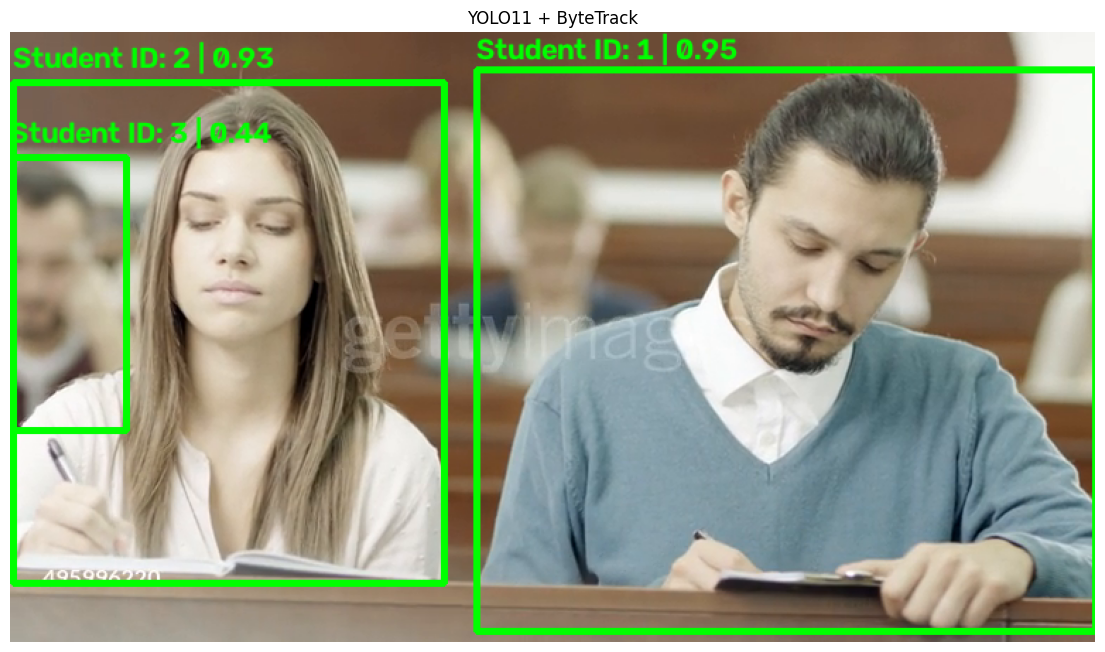

In [9]:
model = YOLO("yolo11n.pt")

cap = cv2.VideoCapture(str(sample_video))

tracked_preview = None

for frame_index in range(min(60, total_frames)):
    ok, frame = cap.read()

    if not ok:
        break

    result = model.track(
        source=frame,
        persist=True,
        tracker="bytetrack.yaml",
        classes=[0],
        conf=0.35,
        device=DEVICE,
        verbose=False
    )[0]

    annotated = frame.copy()

    if result.boxes is not None and result.boxes.id is not None:
        boxes = result.boxes.xyxy.cpu().numpy()
        ids = result.boxes.id.int().cpu().tolist()
        confidences = result.boxes.conf.cpu().tolist()

        for box, track_id, conf in zip(boxes, ids, confidences):
            x1, y1, x2, y2 = map(int, box)

            color = (0, 255, 0)

            cv2.rectangle(
                annotated,
                (x1, y1),
                (x2, y2),
                color,
                3
            )

            label = f"Student ID: {track_id} | {conf:.2f}"

            cv2.putText(
                annotated,
                label,
                (x1, max(20, y1 - 10)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                color,
                2
            )

    tracked_preview = annotated

cap.release()

if tracked_preview is not None:
    plt.figure(figsize=(14, 8))
    plt.imshow(cv2.cvtColor(tracked_preview, cv2.COLOR_BGR2RGB))
    plt.title("YOLO11 + ByteTrack")
    plt.axis("off")
    plt.show()


## 11. Function to track a complete video

This function:
- reads every frame,
- runs YOLO11 person detection,
- applies ByteTrack,
- keeps a Track ID for each student,
- draws green boxes,
- saves the processed video.


In [10]:
def track_students_in_video(
    input_video,
    output_video,
    conf=0.35,
    tracker="bytetrack.yaml"
):
    tracking_model = YOLO("yolo11n.pt")

    cap = cv2.VideoCapture(str(input_video))

    if not cap.isOpened():
        raise RuntimeError(f"Cannot open video: {input_video}")

    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    fourcc = cv2.VideoWriter_fourcc(*"mp4v")

    writer = cv2.VideoWriter(
        str(output_video),
        fourcc,
        fps,
        (width, height)
    )

    frame_count = 0
    all_track_ids = set()

    while True:
        ok, frame = cap.read()

        if not ok:
            break

        result = tracking_model.track(
            source=frame,
            persist=True,
            tracker=tracker,
            classes=[0],
            conf=conf,
            device=DEVICE,
            verbose=False
        )[0]

        annotated = frame.copy()

        if result.boxes is not None and result.boxes.id is not None:
            boxes = result.boxes.xyxy.cpu().numpy()
            ids = result.boxes.id.int().cpu().tolist()
            confidences = result.boxes.conf.cpu().tolist()

            for box, track_id, confidence in zip(
                boxes,
                ids,
                confidences
            ):
                x1, y1, x2, y2 = map(int, box)

                all_track_ids.add(track_id)

                color = (0, 255, 0)

                cv2.rectangle(
                    annotated,
                    (x1, y1),
                    (x2, y2),
                    color,
                    3
                )

                cv2.putText(
                    annotated,
                    f"Student ID: {track_id} | {confidence:.2f}",
                    (x1, max(20, y1 - 10)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.7,
                    color,
                    2
                )

        writer.write(annotated)

        frame_count += 1

        if frame_count % 50 == 0:
            print(
                f"{input_video.name}: "
                f"{frame_count}/{total_frames} frames processed"
            )

    cap.release()
    writer.release()

    print()
    print("Finished:", input_video.name)
    print("Saved to:", output_video)
    print("Unique Track IDs detected:", len(all_track_ids))
    print("Track IDs:", sorted(all_track_ids))

    return {
        "video": input_video.name,
        "output": str(output_video),
        "frames": frame_count,
        "unique_track_ids": len(all_track_ids),
        "track_ids": sorted(all_track_ids)
    }


## 12. Process one complete video

In [11]:
INPUT_VIDEO = video_files[0]

OUTPUT_VIDEO = (
    TRACKING_OUTPUT_DIR /
    f"{INPUT_VIDEO.stem}_tracked.mp4"
)

tracking_summary = track_students_in_video(
    INPUT_VIDEO,
    OUTPUT_VIDEO
)

tracking_summary


video1.mp4: 50/488 frames processed
video1.mp4: 100/488 frames processed
video1.mp4: 150/488 frames processed
video1.mp4: 200/488 frames processed
video1.mp4: 250/488 frames processed
video1.mp4: 300/488 frames processed
video1.mp4: 350/488 frames processed
video1.mp4: 400/488 frames processed
video1.mp4: 450/488 frames processed

Finished: video1.mp4
Saved to: /content/drive/MyDrive/cheating tracking/outputs/tracking/video1_tracked.mp4
Unique Track IDs detected: 9
Track IDs: [1, 2, 3, 4, 7, 8, 12, 14, 15]


{'video': 'video1.mp4',
 'output': '/content/drive/MyDrive/cheating tracking/outputs/tracking/video1_tracked.mp4',
 'frames': 488,
 'unique_track_ids': 9,
 'track_ids': [1, 2, 3, 4, 7, 8, 12, 14, 15]}

## 13. Preview the tracked video

In [12]:
display(
    Video(
        str(OUTPUT_VIDEO),
        embed=True,
        width=900
    )
)


Output hidden; open in https://colab.research.google.com to view.

## 14. Optional — Process all videos

Run this only after verifying that the first tracked video looks correct.


In [13]:
all_tracking_results = []

for video_path in video_files:
    output_path = (
        TRACKING_OUTPUT_DIR /
        f"{video_path.stem}_tracked.mp4"
    )

    result = track_students_in_video(
        video_path,
        output_path
    )

    all_tracking_results.append(result)

tracking_results_df = pd.DataFrame(all_tracking_results)
tracking_results_df


video1.mp4: 50/488 frames processed
video1.mp4: 100/488 frames processed
video1.mp4: 150/488 frames processed
video1.mp4: 200/488 frames processed
video1.mp4: 250/488 frames processed
video1.mp4: 300/488 frames processed
video1.mp4: 350/488 frames processed
video1.mp4: 400/488 frames processed
video1.mp4: 450/488 frames processed

Finished: video1.mp4
Saved to: /content/drive/MyDrive/cheating tracking/outputs/tracking/video1_tracked.mp4
Unique Track IDs detected: 9
Track IDs: [1, 2, 3, 4, 7, 8, 12, 14, 15]
video2.mp4: 50/261 frames processed
video2.mp4: 100/261 frames processed
video2.mp4: 150/261 frames processed
video2.mp4: 200/261 frames processed
video2.mp4: 250/261 frames processed

Finished: video2.mp4
Saved to: /content/drive/MyDrive/cheating tracking/outputs/tracking/video2_tracked.mp4
Unique Track IDs detected: 19
Track IDs: [1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 14, 15, 17, 18, 19, 20, 22, 23]
video3.mp4: 50/256 frames processed
video3.mp4: 100/256 frames processed
video3.mp4: 

,video,output,frames,unique_track_ids,track_ids
0,video1.mp4,/content/drive/MyDrive/cheating tracking/outpu...,488,9,"[1, 2, 3, 4, 7, 8, 12, 14, 15]"
1,video2.mp4,/content/drive/MyDrive/cheating tracking/outpu...,261,19,"[1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 14, 15, 1..."
2,video3.mp4,/content/drive/MyDrive/cheating tracking/outpu...,256,10,"[1, 2, 3, 4, 5, 7, 8, 11, 12, 13]"
3,video4.mp4,/content/drive/MyDrive/cheating tracking/outpu...,226,4,"[1, 2, 3, 5]"
